# OLAP on the weather cube

The five OLAP operations (**roll-up, drill-down, slice, dice, pivot**) and a **GROUP BY CUBE** query, run live on the `weather_dwh` warehouse. The SQL lives in `scripts/olap_queries.py` (tested in `tests/test_olap_views.py`); this notebook only calls it and shows the results.

**Cube.** Dimensions: source (`dim_source`), location (`dim_location`), and time with the concept hierarchy hour → day → month → quarter → year (`dim_date`, `dim_time`, Vietnam local calendar). The base cuboid is `fact_weather_observation`: one source × one location × one UTC hour. Two sub-cubes are precomputed as materialized views (`sql/06_olap_cubes.sql`): `mv_obs_daily` (source × location × day) and `mv_obs_monthly` (source × location × month). They are refreshed and checked against their views after every load (`scripts/refresh_olap_cubes.py`).

**Data scope.** Real data, 2016–2025: Open-Meteo and ERA5 for 8 points, Meteostat for HAN (temperature, no station rain). Read-only: nothing in the DW changes.

**Rules.** Rain is summed only within one source × one location and sources are never added together; means come from sums and counts; rates are ratios of summed counts, so they roll up across any dimension. Rainy day = 24 valid rain hours and ≥ 1 mm; rainy season = months 5–10.

**Run.** `make notebook-setup` once, then `make notebook-run NOTEBOOK=olap_demo.ipynb` with the Compose stack running.

In [1]:
import statistics
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import matplotlib.pyplot as plt
import pandas as pd

import olap_queries as oq
from load_gold_observations import get_db_connection

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
conn = get_db_connection()
conn.set_session(readonly=True, autocommit=True)

## 0. The cube and its precomputed sub-cubes

Row counts of the base cuboid and the two materialized sub-cubes, and the same question (rain and rainy days of HAN, Open-Meteo, 2024) answered from the plain view, which aggregates the whole fact table first, and from the precomputed daily cube.

In [2]:
sizes = oq.fetch(
    conn,
    """
    SELECT 'fact_weather_observation (hour)' AS cuboid, count(*) AS rows FROM fact_weather_observation
    UNION ALL SELECT 'mv_obs_daily (day)', count(*) FROM mv_obs_daily
    UNION ALL SELECT 'mv_obs_monthly (month)', count(*) FROM mv_obs_monthly
    """,
)
display(sizes)

question = (
    "SELECT sum(rain_mm) AS rain_mm, count(*) FILTER (WHERE is_rainy_day) AS rainy_days "
    "FROM {table} WHERE source_name = 'Open-Meteo' AND location_code = 'HAN' AND year = 2024"
)


def timed(sql, runs=3):
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        result = oq.fetch(conn, sql)
        times.append((time.perf_counter() - start) * 1000)
    return result, round(statistics.median(times), 1)


rows = []
for table in ("vw_obs_daily", "mv_obs_daily"):
    result, ms = timed(question.format(table=table))
    rows.append({"read from": table, **result.iloc[0].to_dict(), "median_ms": ms})
display(pd.DataFrame(rows))

,cuboid,rows
0,fact_weather_observation (hour),1490237
1,mv_obs_daily (day),62118
2,mv_obs_monthly (month),2057


,read from,rain_mm,rainy_days,median_ms
0,vw_obs_daily,2660.5,175.0,374.3
1,mv_obs_daily,2660.5,175.0,11.5


## 1. Roll-up: day → month → quarter → year

`GROUP BY ROLLUP (year, quarter, month)` over the daily cube for HAN, Open-Meteo, 2024: one row per month, a subtotal per quarter, and the year total. Rain adds up along the time hierarchy of one source and one location.

In [3]:
roll = oq.roll_up(conn, "Open-Meteo", "HAN", 2024)
display(roll)
months = roll[roll["level"] == "month"]
year_row = roll[roll["level"] == "year"].iloc[0]
print(f"Sum of the 12 months: {months['rain_mm'].sum():.1f} mm; year row: {year_row['rain_mm']:.1f} mm")

,level,year,quarter,month,rain_mm,rainy_days,complete_days,temp_mean_c
0,month,2024,1,1,111.2,17,31,17.76
1,month,2024,1,2,27.7,8,29,19.44
2,month,2024,1,3,76.7,11,31,21.66
3,quarter,2024,1,<NA>,215.6,36,91,19.62
4,month,2024,2,4,29.4,7,30,27.84
5,month,2024,2,5,308.3,24,31,27.42
6,month,2024,2,6,538.1,21,30,29.18
7,quarter,2024,2,<NA>,875.8,52,91,28.14
8,month,2024,3,7,541.3,27,31,28.87
9,month,2024,3,8,319.2,24,31,28.8


Sum of the 12 months: 2660.5 mm; year row: 2660.5 mm


## 2. Drill-down: year → month → day → hour

From the 2024 total of HAN down to its months, then to the days of the wettest month, then to the hours of the wettest day of that month.

In [4]:
by_month = oq.drill_down(conn, "Open-Meteo", "HAN", 2024)
display(by_month)
wettest_month = int(by_month.loc[by_month["rain_mm"].idxmax(), "month"])

by_day = oq.drill_down(conn, "Open-Meteo", "HAN", 2024, wettest_month)
print(f"Days of month {wettest_month}, wettest first:")
display(by_day.sort_values("rain_mm", ascending=False).head(5))
wettest_day = by_day.loc[by_day["rain_mm"].idxmax(), "local_date"]

by_hour = oq.drill_down(conn, "Open-Meteo", "HAN", 2024, wettest_month, wettest_day.day)
print(f"Hours of {wettest_day} (local time); rain ending at that hour:")
display(by_hour)
print(f"Sum of the 24 hours: {by_hour['precipitation_mm'].sum():.1f} mm")

,year,month,rain_mm,rainy_days,complete_rain_days,temp_mean_c
0,2024,1,111.2,17,31,17.76
1,2024,2,27.7,8,29,19.44
2,2024,3,76.7,11,31,21.66
3,2024,4,29.4,7,30,27.84
4,2024,5,308.3,24,31,27.42
5,2024,6,538.1,21,30,29.18
6,2024,7,541.3,27,31,28.87
7,2024,8,319.2,24,31,28.8
8,2024,9,629.1,22,30,27.33
9,2024,10,57.7,11,31,25.44


Days of month 9, wettest first:


,local_date,rain_mm,rain_valid_hours,is_rainy_day,temp_mean_c,temp_max_c
6,2024-09-07,114.3,24,True,26.09,27.9
21,2024-09-22,76.8,24,True,25.71,26.7
10,2024-09-11,64.1,24,True,24.93,25.9
29,2024-09-30,56.6,24,True,26.66,29.9
8,2024-09-09,42.3,24,True,26.68,28.2


Hours of 2024-09-07 (local time); rain ending at that hour:


,local_hour,timestamp_utc,precipitation_mm,temperature_c,humidity_percent
0,0,2024-09-06 17:00:00+00:00,0.1,27.9,85
1,1,2024-09-06 18:00:00+00:00,0.6,26.8,91
2,2,2024-09-06 19:00:00+00:00,2.4,26.4,93
3,3,2024-09-06 20:00:00+00:00,2.0,26.2,93
4,4,2024-09-06 21:00:00+00:00,0.7,26.3,92
5,5,2024-09-06 22:00:00+00:00,0.7,26.3,91
6,6,2024-09-06 23:00:00+00:00,1.6,26.2,90
7,7,2024-09-07 00:00:00+00:00,1.9,26.1,90
8,8,2024-09-07 01:00:00+00:00,2.4,26.1,90
9,9,2024-09-07 02:00:00+00:00,3.2,26.2,90


Sum of the 24 hours: 114.3 mm


## 3. Slice: time = 2024

Fixing one value on the time dimension leaves the source × location plane. Each source keeps its own columns: the rain of Open-Meteo and ERA5 is compared, never added. Meteostat has temperature only, at HAN.

In [5]:
display(oq.slice_year(conn, 2024))

,location_code,rain_open_meteo_mm,rain_era5_mm,temp_open_meteo_c,temp_era5_c,temp_meteostat_c
0,HAN,2660.5,2239.26,24.62,25.26,25.16
1,HBI,2181.2,2347.57,24.92,23.57,<NA>
2,HPH,2367.8,2368.61,24.57,25.18,<NA>
3,LCA,2392.6,2489.81,24.01,22.05,<NA>
4,NBI,1979.7,2213.82,24.8,25.3,<NA>
5,PTO,2414.8,2234.12,24.56,25.03,<NA>
6,TNG,2304.7,2861.32,24.17,24.6,<NA>
7,TUQ,2341.2,2495.91,23.77,24.72,<NA>


## 4. Dice: Open-Meteo × {HAN, LCA} × rainy-season months × 2020–2025

Selecting values on several dimensions at once gives a smaller sub-cube: one source, two locations (the capital and the mountain point), months 5–10, and six years.

In [6]:
display(oq.dice(conn, "Open-Meteo", ["HAN", "LCA"], (5, 10), (2020, 2025)))

,location_code,year,rain_mm,rainy_days,complete_days,rainy_day_pct
0,HAN,2020,1843.2,113,184,61.4
1,HAN,2021,1535.4,112,184,60.9
2,HAN,2022,1918.0,117,184,63.6
3,HAN,2023,1464.5,105,184,57.1
4,HAN,2024,2393.7,129,184,70.1
5,HAN,2025,2016.0,127,184,69.0
6,LCA,2020,2679.4,151,184,82.1
7,LCA,2021,2009.5,143,184,77.7
8,LCA,2022,1513.0,129,184,70.1
9,LCA,2023,1187.7,118,184,64.1


## 5. Pivot: swap the axes

Mean monthly rain (mm) of Open-Meteo over the complete months of 2016–2025. First with locations as rows and months as columns, then rotated so that months are rows and locations are columns. The values do not change; only the view does.

In [7]:
wide = oq.pivot_monthly_rain(conn, "Open-Meteo", (2016, 2025)).set_index("location_code")
display(wide)
rotated = wide.drop(columns="months_used").T
rotated.index = range(1, 13)
rotated.index.name = "month"
display(rotated)

,m01,m02,m03,m04,m05,m06,m07,m08,m09,m10,m11,m12,months_used
location_code,,,,,,,,,,,,,
HAN,60,51,71,103,225,281,329,433,352,203,59,34,119
HBI,57,43,58,106,224,223,309,417,331,199,60,36,119
HPH,43,46,43,90,202,239,312,453,341,165,48,25,119
LCA,230,146,188,200,288,373,355,413,309,222,113,125,119
NBI,50,39,53,89,193,176,306,378,353,231,92,44,119
PTO,76,47,79,139,273,280,329,433,351,203,68,44,119
TNG,75,66,75,101,249,321,338,435,327,186,53,38,119
TUQ,73,50,81,106,264,312,338,423,325,161,60,32,119


location_code,HAN,HBI,HPH,LCA,NBI,PTO,TNG,TUQ
month,,,,,,,,
1,60,57,43,230,50,76,75,73
2,51,43,46,146,39,47,66,50
3,71,58,43,188,53,79,75,81
4,103,106,90,200,89,139,101,106
5,225,224,202,288,193,273,249,264
6,281,223,239,373,176,280,321,312
7,329,309,312,355,306,329,338,338
8,433,417,453,413,378,433,435,423
9,352,331,341,309,353,351,327,325


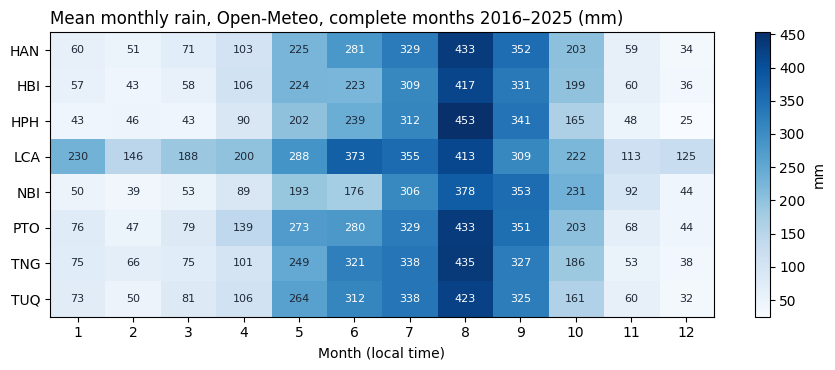

In [8]:
values = wide.drop(columns="months_used").astype(float)
fig, ax = plt.subplots(figsize=(9, 3.8))
image = ax.imshow(values.to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(12), [str(m) for m in range(1, 13)])
ax.set_yticks(range(len(values)), values.index)
ax.set_xlabel("Month (local time)")
ax.set_title("Mean monthly rain, Open-Meteo, complete months 2016–2025 (mm)", loc="left")
for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        v = values.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if v > values.to_numpy().max() * 0.6 else "#1f2937")
fig.colorbar(image, ax=ax, label="mm")
plt.tight_layout()
plt.show()

## 6. GROUP BY CUBE: every combination of location and season

`GROUP BY source_name, CUBE (location_code, season)` computes all four cuboids of the location × season plane in one query: location × season, location only, season only, and the grand total (rows marked `(all …)`). The source stays in the grouping, so sources are never combined. The rainy-day share is rainy days / complete days and the mean temperature is a sum over valid hours, so every subtotal is exact.

In [9]:
cube = oq.cube_rainy_days(conn, "Open-Meteo", (2016, 2025))
display(cube)

,source_name,location,season,complete_days,rainy_days,rainy_day_pct,temp_mean_c
0,Open-Meteo,HAN,dry (11-4),1812,610,33.7,20.36
1,Open-Meteo,HAN,rainy (5-10),1840,1182,64.2,27.81
2,Open-Meteo,HAN,(all),3652,1792,49.1,24.11
3,Open-Meteo,HBI,dry (11-4),1812,551,30.4,20.83
4,Open-Meteo,HBI,rainy (5-10),1840,1199,65.2,28.0
5,Open-Meteo,HBI,(all),3652,1750,47.9,24.44
6,Open-Meteo,HPH,dry (11-4),1812,552,30.5,20.31
7,Open-Meteo,HPH,rainy (5-10),1840,1228,66.7,27.85
8,Open-Meteo,HPH,(all),3652,1780,48.7,24.11
9,Open-Meteo,LCA,dry (11-4),1812,1131,62.4,19.03


In [10]:
conn.close()